# Bloco 5: Inferência com rótulos imperfeitos

**Pergunta substantiva:** que proporção dos projetos sobre IA quer **PUNIR**? E essa proporção difere entre campos políticos?

Quatro estimadores:

| Estimador | Ideia |
|---|---|
| **Só humanos** | usa apenas a amostra-ouro: sem viés, IC largo |
| **Ingênuo** | trata o LLM como verdade no corpus todo: IC estreito... e errado? |
| **PPI** | LLM no corpus todo, corrigido pelo erro medido na amostra-ouro (Angelopoulos et al., 2023, *Science*) |
| **PPI++** | como o PPI, mas pondera o LLM conforme sua qualidade (λ) |

Com $y$ = rótulo humano, $f$ = rótulo do LLM, $n$ = amostra-ouro e $N$ = não rotulados:

$$\hat\theta_{PPI} = \underbrace{\bar f_N}_{\text{LLM no não rotulado}} - \underbrace{(\bar f_n - \bar y_n)}_{\text{viés medido no ouro}}, \qquad \widehat{\mathrm{EP}} = \sqrt{\tfrac{s^2_{f_N}}{N} + \tfrac{s^2_{f-y}}{n}}$$

Como este é um corpus didático com referência completa (304 ementas), sabemos a "verdade" e podemos checar quem acerta, e com que frequência (simulação).

In [1]:
# === Configuração: funciona localmente e no Google Colab ===
import os, sys, subprocess
from pathlib import Path

# PROVISÓRIO: endereço do repositório público do minicurso (ajustar quando publicado)
REPO_URL = "https://github.com/jodavid/minicurso-ia-medicao"

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    if not Path("minicurso-ia-medicao").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    RAIZ = Path("minicurso-ia-medicao").resolve()
else:
    # localmente: a raiz é a pasta do minicurso (este notebook fica em python/)
    RAIZ = Path.cwd().parent if Path.cwd().name == "python" else Path.cwd()

os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "python"))
SAIDA = RAIZ / "resultados" / "python"          # o R grava em resultados/; o Python, aqui
(SAIDA / "figuras").mkdir(parents=True, exist_ok=True)
(SAIDA / "tabelas").mkdir(parents=True, exist_ok=True)
print("Raiz do projeto:", RAIZ)

Raiz do projeto: ~/minicurso_IA_medicao_publico


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from medicao import (CATEGORIAS, PALETA, COR_CAT, AZUIS, CINZA, CINZA_CLARO, CINZA_ESCURO, COR_EST, TINTA2, carrega_corpus, carrega_ouro, carrega_llm,
                     compara_estimadores, resumo_metricas, estilo_graficos)
estilo_graficos()
pct = plt.matplotlib.ticker.PercentFormatter(1)

corpus = carrega_corpus(RAIZ)
ouro = carrega_ouro(RAIZ)
ref = pd.read_csv(RAIZ / "dados/anotacoes/referencia_completa.csv")
llm = carrega_llm(RAIZ)
llm = llm[(llm["temperatura"] > 0) | (llm["semente"] == 42)]   # só as execuções oficiais do material

AVISO: a amostra-ouro ainda NÃO foi revisada por humanos (coluna `revisado`). Os resultados são ilustrativos.


## Instrumento escolhido

O de melhor kappa com temperatura 0 no Bloco 4 (lido da tabela do notebook 04; se ela não existir, recalculado aqui), considerando só execuções que cobrem o corpus inteiro.

In [3]:
n_corpus = len(corpus)
cobertura = llm[llm["temperatura"] == 0].groupby("prompt_id")["doc_id"].nunique()
completos = cobertura[cobertura == n_corpus].index.tolist()
aval = llm[(llm["temperatura"] == 0) & llm["prompt_id"].isin(completos)].merge(ouro[["doc_id", "categoria"]], on="doc_id")
kappas = {p: resumo_metricas(g["categoria"], g["categoria_llm"])["kappa"] for p, g in aval.groupby("prompt_id")}
PROMPT = max(kappas, key=kappas.get)
print("Execuções completas:", completos, "| kappas:", {k: round(v, 3) for k, v in kappas.items()})
print(f"Instrumento usado: s5-nano-instruct, prompt {PROMPT}, temperatura 0")

dados = (corpus[["doc_id", "ano", "campo", "casa"]]
         .merge(llm[(llm["prompt_id"] == PROMPT) & (llm["temperatura"] == 0)][["doc_id", "categoria_llm"]],
                on="doc_id", how="left")
         .merge(ref[["doc_id", "categoria"]].rename(columns={"categoria": "categoria_ref"}), on="doc_id"))
dados["na_ouro"] = dados["doc_id"].isin(ouro["doc_id"])
dados["f"] = (dados["categoria_llm"] == "PUNIR").astype(int)   # falha de formato conta como "não PUNIR"
dados["y"] = np.where(dados["na_ouro"], (dados["categoria_ref"] == "PUNIR").astype(int), np.nan)
verdade = (ref["categoria"] == "PUNIR").mean()
print(f"Proporção PUNIR na referência completa: {verdade:.3f}")

Execuções completas: ['v1', 'v2', 'v3'] | kappas: {'v1': 0.524, 'v2': 0.753, 'v3': 0.75}
Instrumento usado: s5-nano-instruct, prompt v2, temperatura 0
Proporção PUNIR na referência completa: 0.174


## 5.1 Proporção de projetos punitivos

In [4]:
lab, unl = dados[dados["na_ouro"]], dados[~dados["na_ouro"]]
est = compara_estimadores(lab["y"].values, lab["f"].values, unl["f"].values).assign(verdade=verdade)
est.to_csv(SAIDA / "tabelas/estimativas_punir.csv", index=False)
est.round(3)

,estimador,estimativa,ep,li,ls,lambda,verdade
0,Só humanos (amostra-ouro),0.183,0.035,0.114,0.253,NaN,0.174
1,Ingênuo (LLM = verdade),0.230,0.024,0.183,0.278,NaN,0.174
2,PPI,0.206,0.036,0.136,0.276,NaN,0.174
3,PPI++,0.194,0.026,0.144,0.245,0.493,0.174


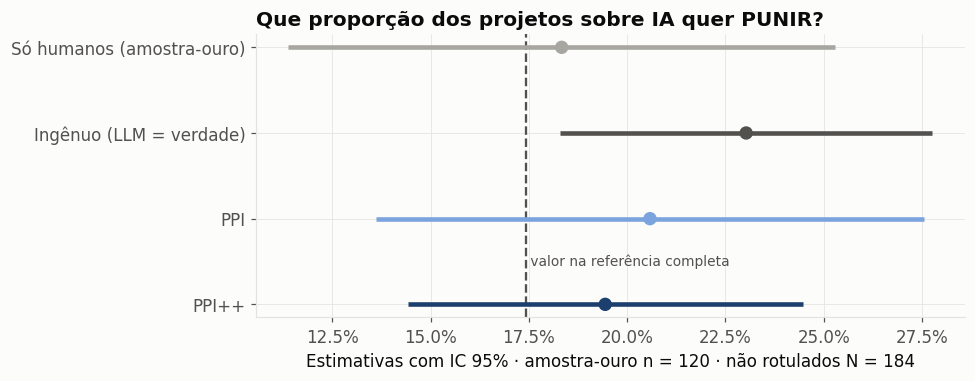

In [5]:
e = est.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axvline(verdade, color=CINZA_ESCURO, lw=1.5, ls="--")
ax.text(verdade, 0.45, " valor na referência completa", color=TINTA2, fontsize=9)
ax.hlines(e["estimador"], e["li"], e["ls"], color=e["estimador"].map(COR_EST), lw=3)
ax.scatter(e["estimativa"], e["estimador"], color=e["estimador"].map(COR_EST), s=60, zorder=3)
ax.xaxis.set_major_formatter(pct)
ax.set_title("Que proporção dos projetos sobre IA quer PUNIR?")
ax.set_xlabel(f"Estimativas com IC 95% · amostra-ouro n = {len(lab)} · não rotulados N = {len(unl)}")
fig.tight_layout(); fig.savefig(SAIDA / "figuras/05_estimadores_punir.png", dpi=200)

## 5.2 Por campo político do autor

In [6]:
linhas = []
for campo, d in dados[dados["campo"].isin(["Esquerda", "Centro", "Direita"])].groupby("campo"):
    l, u = d[d["na_ouro"]], d[~d["na_ouro"]]
    linhas.append(compara_estimadores(l["y"].values, l["f"].values, u["f"].values)
                  .assign(campo=campo, n_ouro=len(l), verdade=(d["categoria_ref"] == "PUNIR").mean()))
por_campo = pd.concat(linhas, ignore_index=True)
por_campo.to_csv(SAIDA / "tabelas/estimativas_punir_campo.csv", index=False)
por_campo.round(3)

,estimador,estimativa,ep,li,ls,lambda,campo,n_ouro,verdade
0,Só humanos (amostra-ouro),0.161,0.067,0.030,0.293,NaN,Centro,31,0.131
1,Ingênuo (LLM = verdade),0.230,0.054,0.123,0.336,NaN,Centro,31,0.131
2,PPI,0.234,0.088,0.061,0.407,NaN,Centro,31,0.131
3,PPI++,0.188,0.054,0.082,0.294,0.368,Centro,31,0.131
4,Só humanos (amostra-ouro),0.154,0.051,0.055,0.253,NaN,Direita,52,0.174
5,Ingênuo (LLM = verdade),0.219,0.033,0.154,0.285,NaN,Direita,52,0.174
6,PPI,0.195,0.050,0.097,0.292,NaN,Direita,52,0.174
7,PPI++,0.174,0.036,0.103,0.245,0.488,Direita,52,0.174
8,Só humanos (amostra-ouro),0.182,0.068,0.048,0.315,NaN,Esquerda,33,0.188
9,Ingênuo (LLM = verdade),0.225,0.047,0.133,0.317,NaN,Esquerda,33,0.188


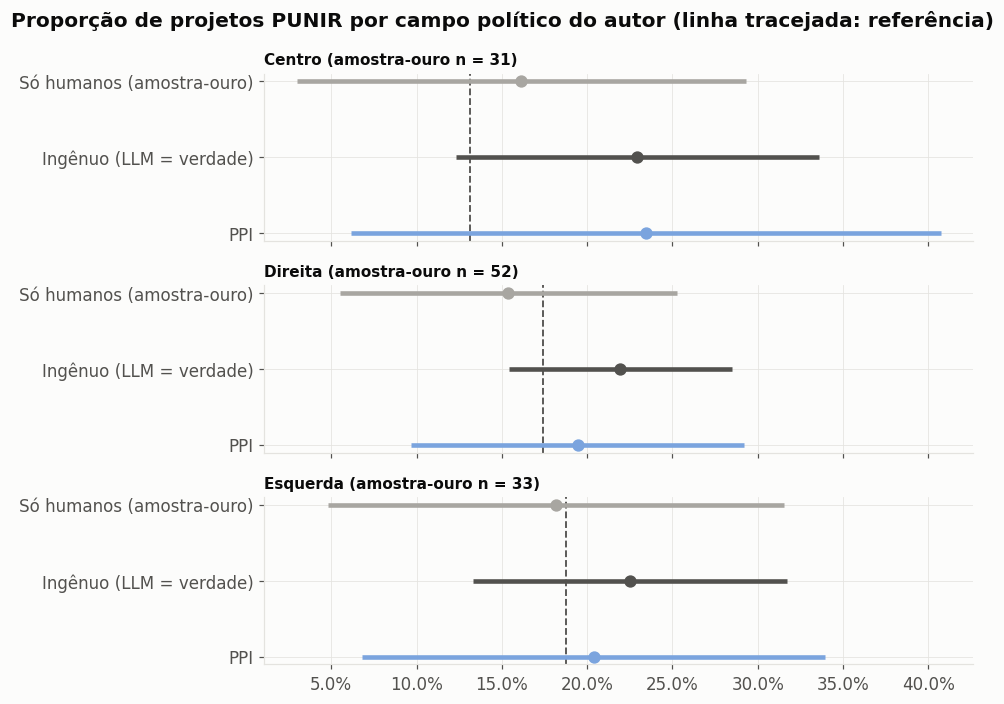

In [7]:
ests = ["Só humanos (amostra-ouro)", "Ingênuo (LLM = verdade)", "PPI"]
cores = COR_EST
fig, axs = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True)
for ax, campo in zip(axs, ["Centro", "Direita", "Esquerda"]):
    d = por_campo[(por_campo["campo"] == campo) & por_campo["estimador"].isin(ests)].iloc[::-1]
    ax.axvline(d["verdade"].iloc[0], color=CINZA_ESCURO, lw=1.2, ls="--")
    for _, r in d.iterrows():
        ax.hlines(r.estimador, max(r.li, 0), r.ls, color=cores[r.estimador], lw=3)
        ax.scatter(r.estimativa, r.estimador, color=cores[r.estimador], s=50, zorder=3)
    ax.set_title(f"{campo} (amostra-ouro n = {d['n_ouro'].iloc[0]})", fontsize=10)
axs[-1].xaxis.set_major_formatter(pct)
fig.suptitle("Proporção de projetos PUNIR por campo político do autor (linha tracejada: referência)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(SAIDA / "figuras/06_punir_por_campo.png", dpi=200)

## 5.3 Simulação: cobertura e largura dos ICs

Repetimos o sorteio da amostra-ouro muitas vezes. Um bom IC de 95% deve conter a verdade em ~95% das repetições.

In [8]:
def simula(n_ouro, B=1000, semente=1):
    rng = np.random.default_rng(semente)
    y_todos = (dados["categoria_ref"] == "PUNIR").astype(int).values
    f_todos = dados["f"].values
    res = []
    for _ in range(B):
        idx = rng.choice(len(dados), n_ouro, replace=False)
        mask = np.zeros(len(dados), bool); mask[idx] = True
        res.append(compara_estimadores(y_todos[mask], f_todos[mask], f_todos[~mask]))
    r = pd.concat(res)
    r["cobre"] = (r["li"] <= verdade) & (verdade <= r["ls"])
    r["largura"] = r["ls"] - r["li"]
    return (r.groupby("estimador", sort=False)
             .agg(cobertura=("cobre", "mean"), largura_media=("largura", "mean"), media=("estimativa", "mean"))
             .assign(vies=lambda x: x["media"] - verdade, n_ouro=n_ouro).drop(columns="media").reset_index())

sim = pd.concat([simula(n) for n in (30, 60, 120)], ignore_index=True)
sim.to_csv(SAIDA / "tabelas/simulacao_cobertura.csv", index=False)
sim.round(3)

,estimador,cobertura,largura_media,vies,n_ouro
0,Só humanos (amostra-ouro),0.897,0.267,-0.001,30
1,Ingênuo (LLM = verdade),0.000,0.095,0.056,30
2,PPI,0.846,0.188,-0.002,30
3,PPI++,0.869,0.160,-0.014,30
4,Só humanos (amostra-ouro),0.971,0.192,0.001,60
5,Ingênuo (LLM = verdade),0.000,0.095,0.056,60
6,PPI,0.974,0.157,-0.001,60
7,PPI++,0.970,0.125,-0.005,60
8,Só humanos (amostra-ouro),0.989,0.136,0.001,120
9,Ingênuo (LLM = verdade),0.000,0.095,0.056,120


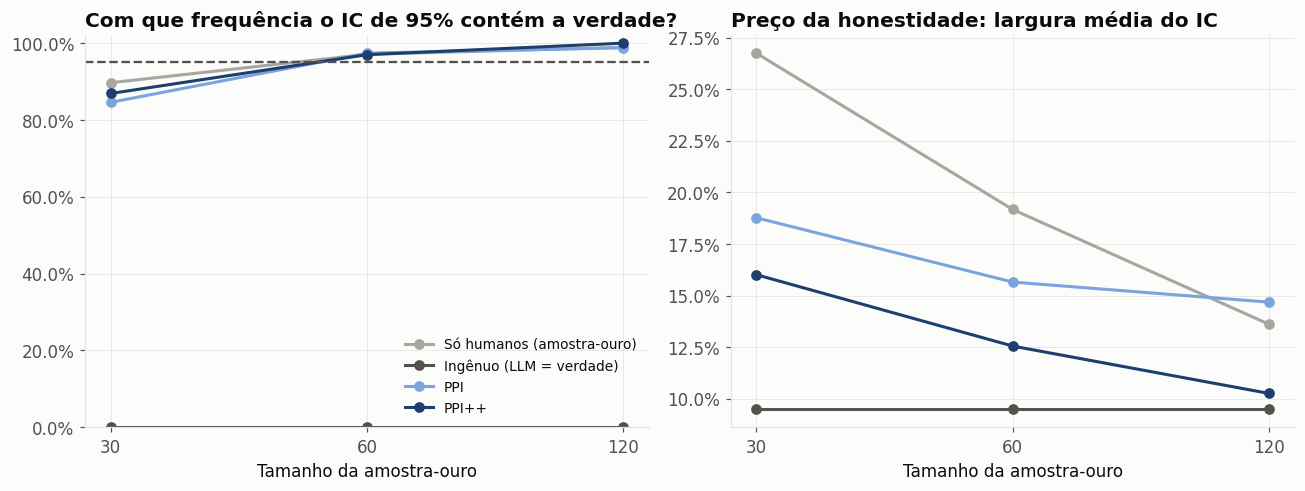

In [9]:
cores = COR_EST
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
for nome, d in sim.groupby("estimador", sort=False):
    axs[0].plot(d["n_ouro"].astype(str), d["cobertura"], "o-", color=cores[nome], lw=2, label=nome)
    axs[1].plot(d["n_ouro"].astype(str), d["largura_media"], "o-", color=cores[nome], lw=2, label=nome)
axs[0].axhline(.95, color=TINTA2, ls="--"); axs[0].set_ylim(0, 1.02)
axs[0].set_title("Com que frequência o IC de 95% contém a verdade?")
axs[1].set_title("Preço da honestidade: largura média do IC")
for ax in axs:
    ax.yaxis.set_major_formatter(pct); ax.set_xlabel("Tamanho da amostra-ouro")
axs[0].legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout(); fig.savefig(SAIDA / "figuras/07_08_simulacao.png", dpi=200)

### Para discutir
* O estimador ingênuo tem o IC mais estreito. Por que isso **não** é uma virtude?
* Quando o PPI++ se aproxima do "só humanos"? (dica: olhe o `lambda`)
* Se o LLM tivesse viés diferencial por campo, qual estimador protegeria a comparação entre campos?

categoria,PUNIR,REGULAR,PROMOVER,OUTRO
ano,,,,
2023,14,20,4,2
2024,11,33,6,5
2025,6,41,28,4
2026,22,50,16,32


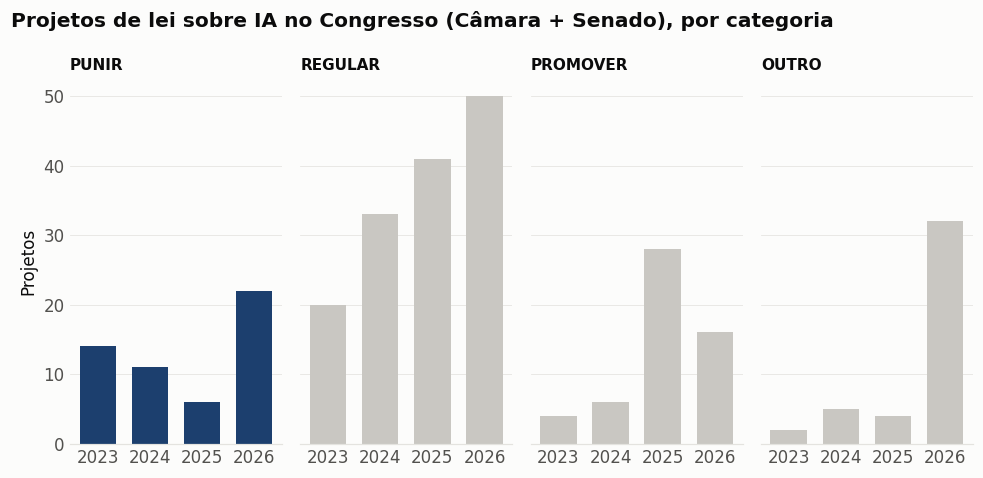

In [10]:
# Retrato descritivo: a explosão legislativa sobre IA
tab = (corpus.merge(ref[["doc_id", "categoria"]], on="doc_id").query("ano >= 2023")
       .pivot_table(index="ano", columns="categoria", values="doc_id", aggfunc="count", fill_value=0)[CATEGORIAS])
# Um painel por categoria; PUNIR (a pergunta do minicurso) em azul, o resto em cinza
fig, axs = plt.subplots(1, 4, figsize=(9, 4.4), sharey=True)
for ax, c in zip(axs, CATEGORIAS):
    ax.bar(tab.index.astype(str), tab[c], color=AZUIS[2] if c == "PUNIR" else CINZA_CLARO, width=.7)
    ax.set_title(c, loc="left", fontsize=10, fontweight="bold")
    ax.grid(axis="x", visible=False)
    for lado in ("top", "right", "left"): ax.spines[lado].set_visible(False)
    ax.set_axisbelow(True); ax.tick_params(length=0)
axs[0].set_ylabel("Projetos")
fig.suptitle("Projetos de lei sobre IA no Congresso (Câmara + Senado), por categoria", x=.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(SAIDA / "figuras/00_projetos_por_ano.png", dpi=200)
tab